<a href="https://colab.research.google.com/github/Sneha-Rani-M/4IK25CS200_DAV_LAB/blob/main/4IK25CS200_EXP_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXP 08: Logistic Regression for Binary Classification

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)
import matplotlib.pyplot as plt

1. Load dataset

In [ ]:
df = pd.read_csv('/content/Titanic-Dataset.csv')

2. Preprocessing

In [ ]:
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'].map({'male':0, 'female':1})
df['Embarked'] = df['Embarked'].map({'S':0, 'C':1, 'Q':2})

3.Feature and Target

In [ ]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
y = df['Survived']

4. Train-test split(80/20)

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

5.Model building

In [ ]:
clf = LogisticRegression(max_iter=1000)
clf.fit(X_tr, y_tr)
y_pred = clf.predict(X_te)

6. Evaluation metrics

In [ ]:
print('Accuracy:', round(accuracy_score(y_te, y_pred), 3))
print('Precision:', round(precision_score(y_te, y_pred), 3))
print('Recall:', round(recall_score(y_te, y_pred), 3))
print('F1-score:', round(f1_score(y_te, y_pred), 3))
print('\n', classification_report(y_te, y_pred))

Accuracy: 0.804
Precision: 0.793
Recall: 0.667
F1-score: 0.724

               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



7. Confusion matrix

Confusion Matrix:
 [[98 12]
 [23 46]]


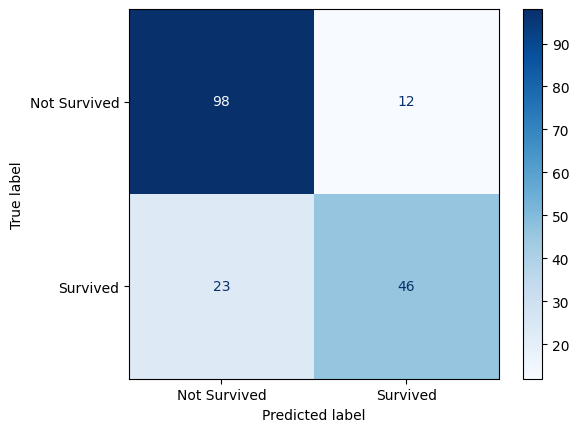

In [ ]:
cm = confusion_matrix(y_te, y_pred, labels=[0,1])
print('Confusion Matrix:\n',cm)
ConfusionMatrixDisplay(cm, display_labels=['Not Survived', 'Survived']).plot(cmap='Blues')
plt.show()